**EEG–Eye-Tracking Multimodal Research | Presented by: Reza Saadatyar (2026)**

**04 | Classical Unimodal Models and EEG–Gaze Fusion**

![Classical EEG-only, gaze-only and fusion comparison on independent-person Validation](../../images/04_unimodal_baselines_and_classical_fusion.svg)

**Research question:** Does combining EEG and gaze window-mean features improve NR/TSR task classification beyond either modality alone?

**Design:** Seven predefined candidates comprise a class-prior reference, EEG-only and gaze-only logistic/forest models, **early fusion** of the eight features and **fixed equal-weight late fusion** of two logistic probability outputs. Models are trained on **371 windows from 11 people** and compared on **99 Validation windows from three other people**.

**Main finding:** **Gaze Random Forest** achieves the highest classical Validation **Macro F1 (0.6244)**, with Balanced Accuracy **0.6231**. Late fusion reaches **0.5643** and early-fusion logistic regression **0.4518**. Neither fusion approach improves on the strongest unimodal model in this comparison.

**Scope:** These results compare NR/TSR task classification on **three Validation participants**. Test was not scored in this modelling stage; the completed held-out evaluation is reported in [Notebook 06](06_robustness_and_final_evaluation.ipynb).

**00. Colab Repository Setup**

In [ ]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(
        ["git", "clone", "-q", repo_url, str(repo_path)], check=True
    )

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("eeg_eye_tracking_fusion")

# ---------------------------- 2. Standard Library ----------------------------
import importlib.util
import json
import random
import shutil
import sys

# ---------------------- 3. Colab Dependency Preparation ----------------------
if importlib.util.find_spec("mne") is None:
    subprocess.run(
        [sys.executable, "-m", "pip", "-q", "install",
         "mne>=1.6,<2"],
        check=True,
    )

# ----------------- 4. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 5. Machine Learning and Deep Learning -------------------
import joblib
from sklearn.metrics import ConfusionMatrixDisplay

# ------------------- 6. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style

# ----------------- 7. Shared and Project Research Utilities ------------------
from core.output_download import download_outputs_from_colab
from models import (
    CLASSICAL_ORDER, CLASS_TO_INDEX, estimator, matrix, metrics,
    probabilities, record_predictions, participant_prediction_metrics,
)

# ---------------------------- 8. Reproducibility -----------------------------
SEED = 17
random.seed(SEED)
np.random.seed(SEED)

# ------------------- 9. Output Directory and Setup Summary -------------------
work = root / "eeg_eye_tracking_fusion"
output_dir = work / "output"
output_dir.mkdir(parents=True, exist_ok=True)
raw_dir = Path("/content/zuco2_source_cache")
raw_dir.mkdir(parents=True, exist_ok=True)
plot_style(font_family="DejaVu Sans", figure_dpi=100)
print("Project outputs:", output_dir)
print("Temporary source cache:", raw_dir)
print("Python:", sys.version.split()[0])
print("Free disk (GiB):", round(
    shutil.disk_usage("/content").free / 2**30, 2,
))


Local changes kept; continuing with the current checkout. Conflicting Git update deferred.
Project outputs: /content/Eye-Tracking-Neurocognitive-Intelligence/eeg_eye_tracking_fusion/output
Temporary source cache: /content/zuco2_source_cache
Python: 3.13.18
Free disk (GiB): 103.99


**02. Recover the Participant-Disjoint Feature Set**

The current `03_features.csv` contains **630 paired windows**, each with four EEG and four gaze window-mean predictors. Source IDs and roles agree with the original paired-window registry.

| Partition | Independent people | Windows | NR / TSR |
| --- | ---: | ---: | ---: |
| Train | **11** | **371** | 201 / 170 |
| Validation | **3** | **99** | 60 / 39 |
| Reserved Test | **4** | **160** | 80 / 80 |

Only EEG/gaze measurements enter the predictor matrices. Participant IDs, run labels and split names are preserved for grouping, not used as explanatory variables. This distinction is essential for a fair unseen-participant comparison.

In [3]:
# ============== 02. Load Paired Feature Table and Fixed Labels ===============

required = ["02_window_registry.csv", "03_features.csv"]
missing = [name for name in required if not (output_dir / name).is_file()]
if missing:
    raise FileNotFoundError(
        f"Missing upstream paired-window or feature outputs: {missing}"
    )

table = pd.read_csv(
    output_dir / "03_features.csv", dtype={"participant_id": str}
)
registry = pd.read_csv(
    output_dir / "02_window_registry.csv", dtype={"participant_id": str}
)
expected = registry.loc[
    registry.eligible, ["window_id", "participant_id", "task", "split"]
]
if table.empty or table.window_id.duplicated().any():
    raise ValueError("Feature table is empty or contains duplicate windows")
if expected.window_id.duplicated().any():
    raise ValueError("Stage-02 eligible window identities are duplicated")
if set(table.window_id) != set(expected.window_id):
    raise ValueError(
        "Stage-03 feature windows differ from the fixed Stage-02 registry"
    )
matched = table[
    ["window_id", "participant_id", "task", "split"]
].merge(
    expected, on="window_id", how="left",
    validate="one_to_one", suffixes=("_feature", "_registry"),
)
for field in ("participant_id", "task", "split"):
    if (matched[f"{field}_registry"].isna().any() or not
            matched[f"{field}_feature"].eq(
                matched[f"{field}_registry"]
            ).all()):
        raise ValueError(
            f"Stage-03 {field} fields differ from the source window registry"
        )
if not table.groupby("participant_id")["split"].nunique().eq(1).all():
    raise ValueError("A participant appears in multiple split roles")
if not set(table.task).issubset(CLASS_TO_INDEX):
    raise ValueError("Unexpected reading task labels")

train = table.loc[table.split.eq("train")].copy()
valid = table.loc[table.split.eq("validation")].copy()
test = table.loc[table.split.eq("test")].copy()
if min(len(train), len(valid), len(test)) < 1:
    raise ValueError("The original partition has an empty role")
if train.task.nunique() != 2 or valid.task.nunique() != 2:
    raise ValueError("Both task classes must appear in Train and Validation")
y_train = train.task.map(CLASS_TO_INDEX).to_numpy()
y_valid = valid.task.map(CLASS_TO_INDEX).to_numpy()

print("Matched paired feature windows:", len(table))
print("Train:", len(train), "windows /", train.participant_id.nunique(),
      "people")
print("Validation:", len(valid), "windows /",
      valid.participant_id.nunique(), "people")
print("Reserved Test:", len(test), "windows /",
      test.participant_id.nunique(), "people (not scored)")
display(
    table.groupby(["split", "task"])
    .agg(windows=("window_id", "size"),
         people=("participant_id", "nunique"))
    .reset_index()
)


Matched paired feature windows: 630
Train: 371 windows / 11 people
Validation: 99 windows / 3 people
Reserved Test: 160 windows / 4 people (not scored)


,split,task,windows,people
0,test,nr,80,4
1,test,tsr,80,4
2,train,nr,201,11
3,train,tsr,170,11
4,validation,nr,60,3
5,validation,tsr,39,3


**03. Establish Prior and Unimodal Baselines**

The class-prior model uses the **Train label distribution** without signal features. Separate **logistic regression** and **random forest** candidates use either the four EEG means or the four gaze means; imputation and any scaling are fitted on Train only.

The unimodal Validation Macro F1 results are:

| Candidate | Macro F1 |
| --- | ---: |
| **Gaze Random Forest** | **0.6244** |
| Gaze Logistic | 0.5472 |
| EEG Random Forest | 0.5139 |
| EEG Logistic | 0.4545 |
| Class Prior | 0.3774 |

These baselines show the observed effect of different inputs and model families, but do not isolate either effect causally. The constant `gaze_valid_fraction` contributes no variation in this cohort.

In [4]:
# ============ 03. Fit Task Prior and Separate Unimodal Estimators ============

fitted, predictions, records = {}, {}, []
feature_group = {
    'class_prior': 'gaze',
    'gaze_logistic': 'gaze', 'eeg_logistic': 'eeg',
    'early_fusion_logistic': 'fused',
    'gaze_forest': 'gaze', 'eeg_forest': 'eeg',
}
for name in CLASSICAL_ORDER:
    if name == 'late_equal_fusion':
        continue
    group = feature_group[name]
    model = estimator(name, seed=SEED)
    x_train = matrix(train, group)
    x_val = matrix(valid, group)
    model.fit(x_train, y_train)
    proba = probabilities(model, x_val)
    fitted[name] = model
    predictions[name] = proba
    row = {'model': name, 'partition': 'validation',
           'n_windows': len(valid),
           'n_people': valid.participant_id.nunique(),
           **metrics(y_valid, proba.argmax(axis=1))}
    records.append(row)
    joblib.dump(model, output_dir / f'04_{name}.joblib')
    print(name, 'Macro F1:', round(row['macro_f1'], 4))


class_prior Macro F1: 0.3774
gaze_logistic Macro F1: 0.5472
eeg_logistic Macro F1: 0.4545
early_fusion_logistic Macro F1: 0.4518
gaze_forest Macro F1: 0.6244
eeg_forest Macro F1: 0.5139


**04. Compare Early and Late Fusion**

**Early fusion** concatenates the four EEG and four gaze means from each paired window, fitting one logistic-regression pipeline. **Late fusion** averages the probabilities from already fitted EEG- and gaze-logistic models with fixed **0.50/0.50** weights.

On the same **99 Validation windows**, early fusion obtains **Macro F1 0.4518**, and late fusion **0.5643**. Both fall below **Gaze Random Forest (0.6244)**.

**Finding:** Neither tested fusion approach improved on the gaze-only forest in this Validation set. This does not establish that EEG is generally uninformative.

In [5]:
# ============ 04. Fit Early Fusion and Evaluate Fixed Late Fusion ============

late = 0.5 * (predictions['gaze_logistic'] +
              predictions['eeg_logistic'])
predictions['late_equal_fusion'] = late
records.append({
    'model': 'late_equal_fusion', 'partition': 'validation',
    'n_windows': len(valid),
    'n_people': valid.participant_id.nunique(),
    **metrics(y_valid, late.argmax(axis=1))
})
(output_dir / '04_late_fusion.json').write_text(
    json.dumps({'weight_eeg': 0.5, 'weight_gaze': 0.5,
                'components': ['eeg_logistic', 'gaze_logistic']},
               indent=2), encoding='utf-8')
summary = pd.DataFrame(records)
if set(summary.model) != set(CLASSICAL_ORDER):
    raise ValueError("Missing or duplicate classical candidate names")
display(summary.sort_values('macro_f1', ascending=False))


,model,partition,n_windows,n_people,accuracy,macro_f1,balanced_accuracy
4,gaze_forest,validation,99,3,0.646465,0.624390,0.623077
6,late_equal_fusion,validation,99,3,0.585859,0.564345,0.564103
1,gaze_logistic,validation,99,3,0.565657,0.547176,0.547436
5,eeg_forest,validation,99,3,0.515152,0.513912,0.528205
2,eeg_logistic,validation,99,3,0.454545,0.454490,0.473718
3,early_fusion_logistic,validation,99,3,0.454545,0.451805,0.460256
0,class_prior,validation,99,3,0.606061,0.377358,0.500000


**05. Evaluate Class Balance and Participant Variation**

The seven candidates share **99 Validation windows** (**60 NR, 39 TSR**). Accuracy alone could reward prediction of the more common NR class, so the primary comparison uses **fixed-label Macro F1**, supported by Balanced Accuracy.

**Gaze Random Forest:** Accuracy **0.6465**, Macro F1 **0.6244**; **44/60 NR** and **20/39 TSR** windows were classified correctly.

| Validation participant | Windows | Gaze Forest Macro F1 |
| --- | ---: | ---: |
| `sub-YDR` | 31 | **0.7654** |
| `sub-YRH` | 38 | **0.6306** |
| `sub-YTL` | 30 | **0.3478** |

The spread illustrates between-participant variation; 99 windows represent only three independent people. The saved comparison and confusion plots show pooled scores and error patterns.

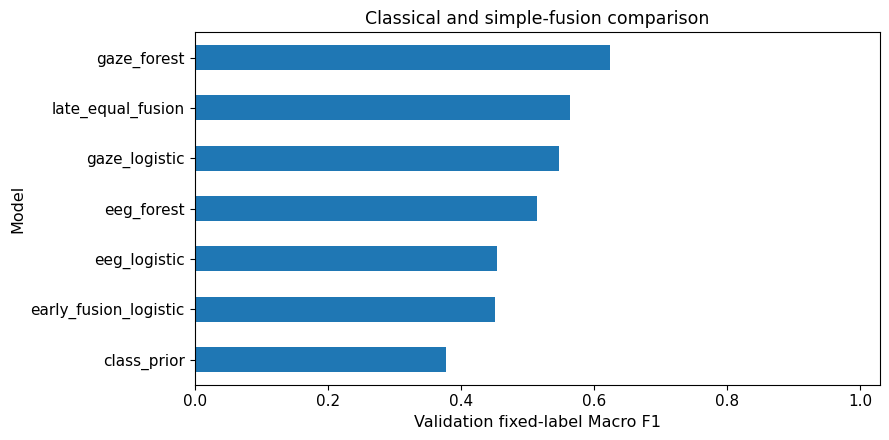

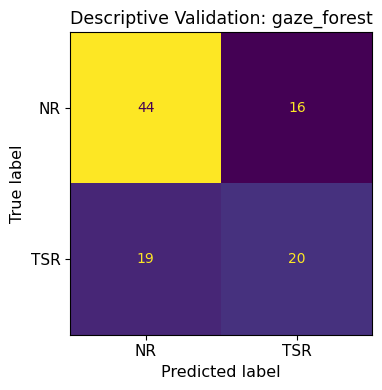

In [6]:
# =========== 05. Compare Validation Metrics and a Confusion Matrix ===========

fig, ax = plt.subplots(figsize=(9, 4.5))
summary.sort_values('macro_f1').plot.barh(
    x='model', y='macro_f1', ax=ax, legend=False)
ax.set(xlabel='Validation fixed-label Macro F1',
       ylabel='Model', xlim=(0, 1.03),
       title='Classical and simple-fusion comparison')
fig.tight_layout()
fig.savefig(output_dir / '04_validation_comparison.png', dpi=170)
plt.show()
best = summary.sort_values(['macro_f1', 'balanced_accuracy'],
                           ascending=False).iloc[0].model
fig, ax = plt.subplots(figsize=(4.3, 4))
ConfusionMatrixDisplay.from_predictions(
    y_valid, predictions[best].argmax(axis=1),
    labels=[0, 1], display_labels=['NR', 'TSR'], ax=ax,
    colorbar=False)
ax.set_title(f'Descriptive Validation: {best}')
fig.tight_layout()
fig.savefig(output_dir / '04_validation_confusion.png', dpi=170)
plt.show()


**06. Preserve Classical Model Evidence**

The stage records **693 Validation predictions** (seven candidates × 99 matched windows), **seven pooled metric rows** and **21 descriptive model/person rows**.

The six fitted estimators are stored as `04_*.joblib`; `04_late_fusion.json` records the fixed probability weights. `04_validation_comparison.png` and `04_validation_confusion.png` display the pooled rankings and Gaze Random Forest's confusion matrix.

Every candidate covers the same source window IDs and class order. The saved metric table is consistent with the predictions, providing a comparable basis for the later ten-model selection.

In [7]:
# ============== 06. Check Probabilities and Save Model Evidence ==============

saved = []
for name in CLASSICAL_ORDER:
    proba = predictions[name]
    if proba.shape != (len(valid), 2):
        raise ValueError(f"Invalid probability dimensions for {name}")
    if not np.isfinite(proba).all():
        raise ValueError(f"Non-finite model probabilities for {name}")
    if not np.allclose(proba.sum(axis=1), 1., atol=1e-5):
        raise ValueError(f"Non-normalised probabilities for {name}")
    saved.append(record_predictions(valid, name, proba))
prediction_table = pd.concat(saved, ignore_index=True)
prediction_table.to_csv(
    output_dir / '04_validation_predictions.csv', index=False)
summary.to_csv(output_dir / '04_validation_metrics.csv', index=False)
print('Validation rows:', len(prediction_table))
model_support = prediction_table.groupby("model")["window_id"].nunique()
if (not model_support.eq(len(valid)).all() or
        prediction_table.duplicated(["model", "window_id"]).any() or
        not prediction_table.window_id.isin(valid.window_id).all()):
    raise ValueError(
        "Saved candidate predictions do not match the fixed Validation IDs"
    )
print("Models with complete Validation predictions:", len(model_support))
print("Independent Validation participants:",
      valid.participant_id.nunique())

# Descriptive model performance per independent Validation participant.
# The primary pooled-window model selection metric remains unchanged.
person_metrics = participant_prediction_metrics(prediction_table)
expected_person_rows = len(CLASSICAL_ORDER) * valid.participant_id.nunique()
person_support = person_metrics.groupby("model")["n_windows"].sum()
if (len(person_metrics) != expected_person_rows or
        not person_support.eq(len(valid)).all()):
    raise ValueError("Incomplete person-level Validation metrics")
person_metrics.to_csv(
    output_dir / "04_validation_person_metrics.csv", index=False)
print("Person-level Validation metric rows:", len(person_metrics))



Validation rows: 693
Models with complete Validation predictions: 7
Independent Validation participants: 3
Person-level Validation metric rows: 21


**07. Interpretation**

Among seven predefined classical and simple-fusion candidates, **Gaze Random Forest** was the strongest on the **three-person Validation partition**. Neither early nor late fusion improved pooled Macro F1 over this gaze-only comparator.

The individual scores (**0.7654, 0.6306, 0.3478**) suggest substantial participant dependence. [Notebook 05](05_temporal_and_advanced_fusion.ipynb) provides a separate temporal comparison using six two-second bins; [Notebook 06](06_robustness_and_final_evaluation.ipynb) reconciles all ten candidates under one selection rule.

**Evaluation boundary:** Notebook 04 uses Validation only. The four-person final Test was subsequently evaluated in [Notebook 06](06_robustness_and_final_evaluation.ipynb); no external validation was conducted.

In [8]:
# ================== 07. Interpretation and Next Dependency ===================

print('Next: 05_temporal_and_advanced_fusion.ipynb')
download_outputs_from_colab("eeg_eye_tracking_fusion/output", "04")


Next: 05_temporal_and_advanced_fusion.ipynb
------------------------------------------------------------------------
Notebook 04
Files packaged: 12
  + 04_class_prior.joblib
  + 04_early_fusion_logistic.joblib
  + 04_eeg_forest.joblib
  + 04_eeg_logistic.joblib
  + 04_gaze_forest.joblib
  + 04_gaze_logistic.joblib
  + 04_late_fusion.json
  + 04_validation_comparison.png
  + 04_validation_confusion.png
  + 04_validation_metrics.csv
  + 04_validation_person_metrics.csv
  + 04_validation_predictions.csv
Download ZIP from Colab Contents: /content/eeg_eye_tracking_fusion_Notebook_04_Outputs.zip
